MACHINE LEARNING PROJECT


Job Salary Prediction Using Machine Learning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score,mean_absolute_error
from joblib import dump, load
import pickle
import warnings
warnings.filterwarnings("ignore")

C:\Users\sabir\AppData\Local\Temp\ipykernel_22748\733048291.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
df=df = pd.read_csv("data/job_salary_prediction_dataset.csv")
df

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
...,...,...,...,...,...,...,...,...,...,...
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467


EDA

In [3]:
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [4]:
df.tail()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467
249999,Data Analyst,16,Diploma,2,Technology,Medium,UK,No,5,133084


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


In [6]:
df.columns

Index(['job_title', 'experience_years', 'education_level', 'skills_count',
       'industry', 'company_size', 'location', 'remote_work', 'certifications',
       'salary'],
      dtype='object')

In [7]:
df.describe()

,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


In [8]:
df.isnull().sum()

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

In [9]:
df.duplicated().any()

False

In [10]:
df.shape

(250000, 10)

In [11]:
df.size

2500000

In [12]:
df['job_title'].value_counts()

job_title
Backend Developer            21125
Cybersecurity Analyst        20959
Product Manager              20950
AI Engineer                  20945
Data Scientist               20890
DevOps Engineer              20889
Software Engineer            20876
Data Analyst                 20722
Cloud Engineer               20686
Machine Learning Engineer    20677
Business Analyst             20648
Frontend Developer           20633
Name: count, dtype: int64

In [13]:
df['industry'].value_counts()

industry
Finance          25393
Consulting       25258
Media            25034
Manufacturing    25024
Technology       24903
Government       24901
Healthcare       24898
Education        24889
Telecom          24859
Retail           24841
Name: count, dtype: int64

In [79]:
df["job_title"].unique()

array([ 0,  5,  8,  2, 10,  1,  9,  7, 11,  4,  6,  3])

Visualizing Using Matplotlib

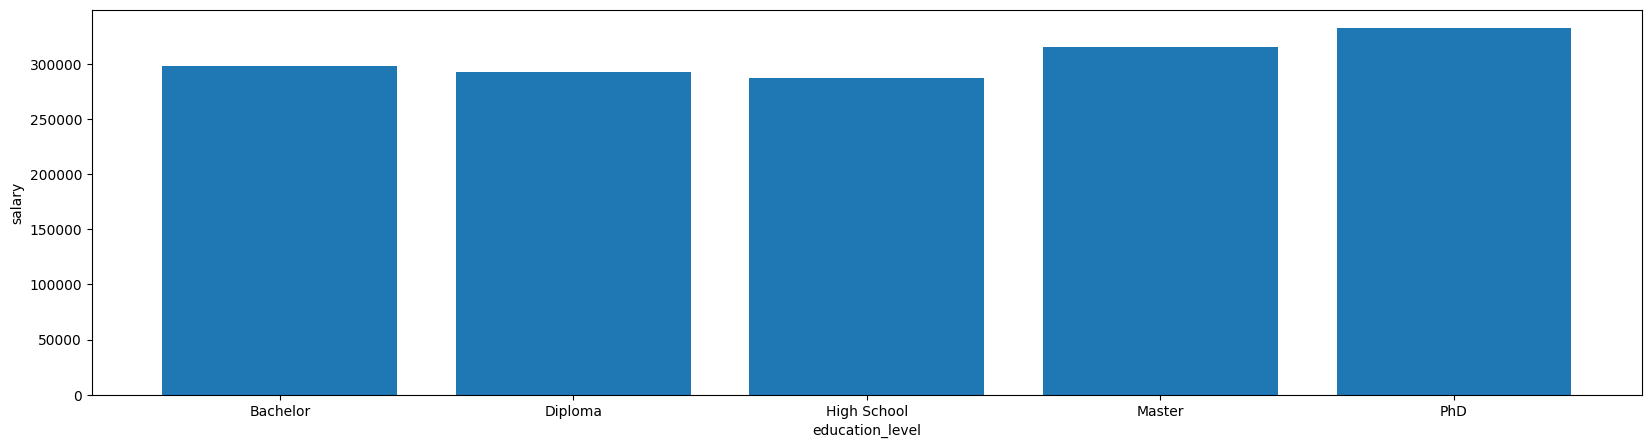

In [14]:
plt.figure(figsize=(20,5))
group=df.groupby("education_level")
grouped=group[["education_level","salary"]].max()
getdata=pd.DataFrame(grouped)
getdata
x=getdata["education_level"].head(10)
y=getdata["salary"].head(10)
plt.bar(x,y)
plt.xlabel("education_level")
plt.ylabel("salary")
plt.show()

SCATTER PLOT

<function matplotlib.pyplot.show(close=None, block=None)>

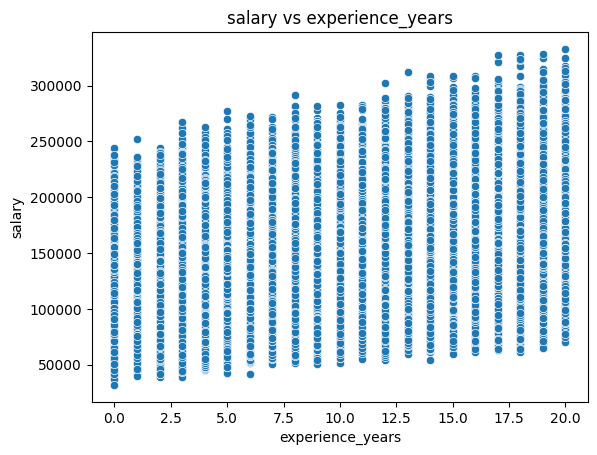

In [15]:
sns.scatterplot(x='experience_years',y='salary', data=df)
plt.title('salary vs experience_years')
plt.show

BAR

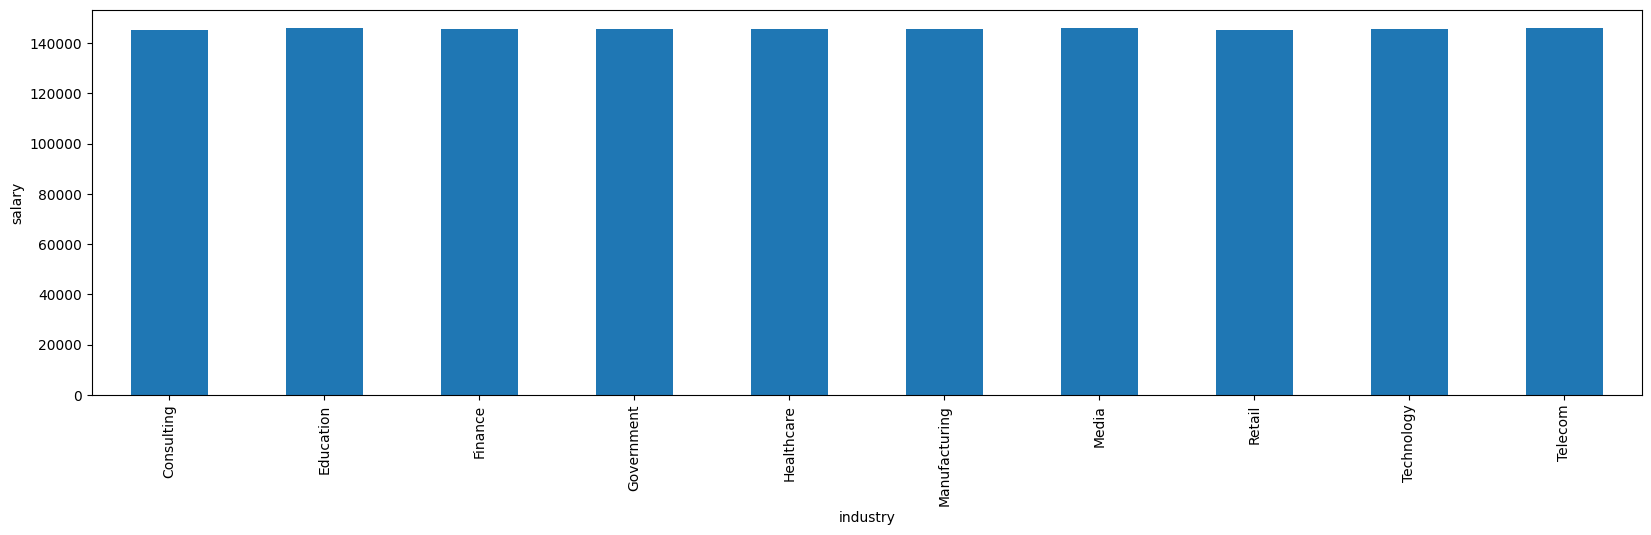

In [16]:
plt.figure(figsize=(20,5))
df.groupby("industry")["salary"].mean().plot(kind='bar')
plt.xlabel("industry")
plt.ylabel("salary")
plt.show()

BOX

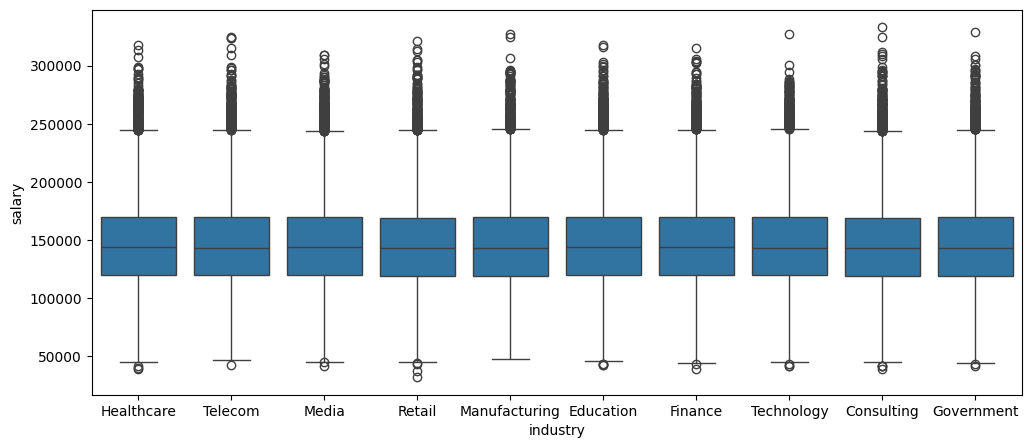

In [17]:
plt.figure(figsize=(12,5))
sns.boxplot(x="industry",y="salary",data=df)
plt.show()

DISPLOT

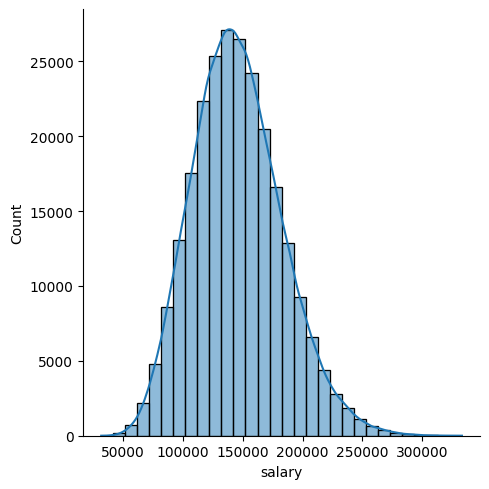

In [18]:
sns.displot(df['salary'],kde=True,bins=30)

CORRELATION

<Axes: >

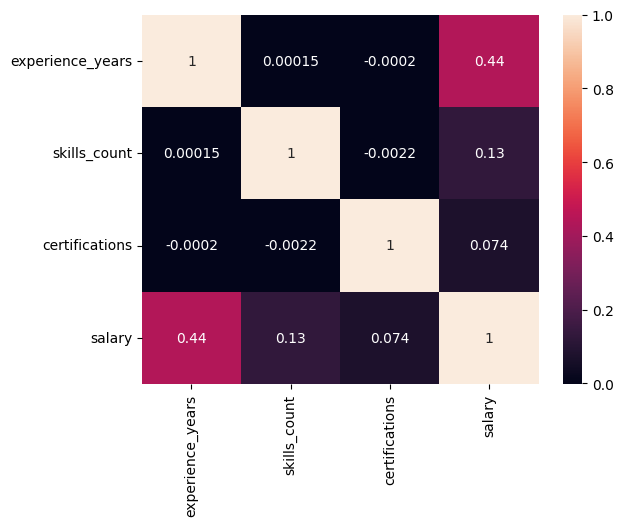

In [19]:
sns.heatmap(df.select_dtypes(['number']).corr(),annot=True)

ENCODING

In [20]:
l1=LabelEncoder()
l2=LabelEncoder()
l3=LabelEncoder()
l4=LabelEncoder()
l5=LabelEncoder()
l6=LabelEncoder()

In [21]:
df['job_title']=l1.fit_transform(df['job_title'])
df['education_level']=l2.fit_transform(df['education_level'])
df['industry']=l3.fit_transform(df['industry'])
df['company_size']=l4.fit_transform(df['company_size'])
df['location']=l5.fit_transform(df['location'])
df['remote_work']=l6.fit_transform(df['remote_work'])


In [22]:
df

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,0,10,0,2,4,2,3,0,2,109413
1,5,5,0,17,9,3,0,1,0,93764
2,8,18,4,4,6,2,6,1,1,148123
3,2,19,4,13,7,2,1,2,0,189123
4,10,15,0,7,5,1,7,2,0,165069
...,...,...,...,...,...,...,...,...,...,...
249995,11,17,4,2,9,0,3,1,1,127791
249996,8,20,4,7,9,4,5,1,2,154593
249997,2,1,0,12,7,0,3,2,0,75988
249998,6,0,2,2,0,3,7,0,5,90467


TARGET VALUE

In [23]:
x=df.drop("salary",axis=1)
x

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications
0,0,10,0,2,4,2,3,0,2
1,5,5,0,17,9,3,0,1,0
2,8,18,4,4,6,2,6,1,1
3,2,19,4,13,7,2,1,2,0
4,10,15,0,7,5,1,7,2,0
...,...,...,...,...,...,...,...,...,...
249995,11,17,4,2,9,0,3,1,1
249996,8,20,4,7,9,4,5,1,2
249997,2,1,0,12,7,0,3,2,0
249998,6,0,2,2,0,3,7,0,5


In [24]:
y=df['salary']
y

0         109413
1          93764
2         148123
3         189123
4         165069
           ...  
249995    127791
249996    154593
249997     75988
249998     90467
249999    133084
Name: salary, Length: 250000, dtype: int64

In [25]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [26]:
scaler=StandardScaler()

In [27]:
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [28]:
x_test

array([[-1.59138565e+00,  1.64366673e-01, -1.41680020e+00, ...,
        -1.21597119e+00, -1.22111150e+00,  2.95419201e-01],
       [ 4.35414604e-01, -4.95922282e-01,  7.04557411e-01, ...,
        -5.19757406e-01, -1.22111150e+00, -8.75127379e-01],
       [ 7.24957498e-01, -7.05565911e-04, -1.41680020e+00, ...,
        -5.19757406e-01,  1.23151062e+00,  1.46596578e+00],
       ...,
       [-4.33214078e-01,  1.48494458e+00, -2.56179186e-03, ...,
        -8.67864299e-01, -1.22111150e+00, -2.89854089e-01],
       [ 1.01450039e+00,  1.64366673e-01, -2.56179186e-03, ...,
        -1.21597119e+00, -1.22111150e+00,  1.46596578e+00],
       [ 1.30404329e+00, -7.05565911e-04, -1.41680020e+00, ...,
        -1.71650514e-01, -1.22111150e+00,  2.95419201e-01]])

In [29]:
x_train.shape


(175000, 9)

In [30]:
y_train.shape

(175000,)

MODEL FITTING


Model 1 LinearRegression

In [31]:
model1=LinearRegression()
model1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [32]:

lineartrain=model1.score(x_train,y_train)*100
lineartrain

45.93151887254773

In [33]:
lineartest=model1.score(x_test,y_test)*100
lineartest

45.76296153905957

In [34]:
ypredlr=model1.predict(x_test)
ypredlr

array([102025.27100443, 127958.6307987 , 109177.69633157, ...,
       131752.22288466, 164026.4419375 , 143630.255806  ])

In [35]:
mae_lr=mean_absolute_error(y_test,ypredlr)
mae_lr

21708.662535827283

In [36]:
r2_lr=r2_score(y_test,ypredlr)
r2_lr

0.45762961539059566

Model 2 DecisionTreeRegressor

In [37]:
model2=DecisionTreeRegressor()
model2.fit(x_train,y_train)


,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max

In [38]:
treetrain=model2.score(x_train,y_train)*100
treetrain

99.99938732225246

In [39]:
treetest=model2.score(x_test,y_test)*100
treetest

92.80067949333906

In [40]:
ypred_dt=model2.predict(x_test)
ypred_dt

array([162052., 101510.,  76962., ..., 138055., 212955., 161932.])

In [41]:
mae_dt=mean_absolute_error(y_test,ypred_dt)
mae_dt

7770.999193333333

In [42]:
r2_dt=r2_score(y_test,ypred_dt)
r2_dt

0.9280067949333907

Model 3 Random Forest Regressor

In [43]:
model3=RandomForestRegressor(n_estimators=50,random_state=1)
model3.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [44]:
ypred_rf=model3.predict(x_test)
ypred_rf

array([168376.4 ,  94987.32,  76879.04, ..., 136585.5 , 214558.76,
       160511.72])

In [45]:
foresttrain=model3.score(x_train,y_train)*100
foresttrain

99.5220741340227

In [46]:
foresttest=model3.score(x_test,y_test)*100
foresttest

96.72971214464192

In [47]:
mae_rf=mean_absolute_error(y_test,ypred_rf)
mae_rf

5342.178536666666

In [48]:
r2_rf=r2_score(y_test,ypred_rf)
r2_rf

0.9672971214464192

Model 4 KNeighborsRegressor

In [49]:
model4=KNeighborsRegressor(n_neighbors=10)
model4.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [50]:
ypred_kn=model4.predict(x_test)
ypred_kn

array([141969.3, 118708.7, 117989.5, ..., 103610.9, 169219.7, 140181.9])

In [51]:
ktrain=model4.score(x_train,y_train)*100
ktrain

72.51512226656149

In [52]:
ktest=model4.score(x_test,y_test)*100
ktest

65.7919110542486

In [53]:
mae_kn=mean_absolute_error(y_test,ypred_kn)
mae_kn

17545.71037333333

In [54]:
r2_kn=r2_score(y_test,ypred_kn)
r2_kn

0.657919110542486

model 5 Adaboost Regressor

In [55]:
model5=AdaBoostRegressor(n_estimators=50,random_state=1)
model5.fit(x_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",1


In [56]:
ypred_ad=model5.predict(x_test)
ypred_ad

array([160499.58832144, 116091.69321245, 110603.52308156, ...,
       141579.10480512, 181059.75131141, 143563.14312218])

In [57]:
Adaboosttrain=model5.score(x_train,y_train)*100
Adaboosttrain

74.6494362924154

In [58]:
Adaboosttest=model5.score(x_test,y_test)*100
Adaboosttest

74.5160577685852

In [59]:
mae_ad=mean_absolute_error(y_test,ypred_ad)
mae_ad

15391.37659895861

In [60]:
r2_ad=r2_score(y_test,ypred_ad)
r2_ad

0.745160577685852

model 6 GradientBoost Regressor

In [61]:
model6=GradientBoostingRegressor(n_estimators=50,random_state=1)
model6.fit(x_train,y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",50
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft c

In [62]:
ypred_gb=model6.predict(x_test)
ypred_gb

array([154469.52098502, 104826.40820055,  93335.93442546, ...,
       144203.00004996, 180606.7444732 , 149806.65685601])

In [63]:
gradienttrain=model6.score(x_train,y_train)*100
gradienttrain

83.85698401480124

In [64]:
gradienttest=model6.score(x_test,y_test)*100
gradienttest

83.7834294604632

In [65]:
mae_gb=mean_absolute_error(y_test,ypred_gb)
mae_gb

12168.894174169487

In [66]:
r2_gb=r2_score(y_test,ypred_gb)
r2_gb

0.837834294604632

model 7 XGB Regressor

In [67]:
model7=XGBRegressor(n_estimators=50,random_state=1)
model7.fit(x_train,y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [68]:
ypred_xgb=model7.predict(x_test)
ypred_xgb

array([169351.73,  93407.59,  76372.65, ..., 140597.28, 208562.72,
       155380.83], dtype=float32)

In [69]:
XGBtrain=model7.score(x_train,y_train)*100
XGBtrain

97.62665629386902

In [70]:
XGBtest=model7.score(x_test,y_test)*100
XGBtest

97.51988649368286

In [71]:
mae_xgb=mean_absolute_error(y_test,ypred_xgb)
mae_xgb

4682.02392578125

In [72]:
r2_xgb=r2_score(y_test,ypred_xgb)
r2_xgb

0.9751988649368286

MODEL TEST,TRAIN,MEAN ABSOLUTE ERROR AND R2 SCORE


In [73]:
score=pd.DataFrame({"Model":['Linear Regression','DecisionTreeRegressor','RandomForestRegressor',
                           'KNeighborRegressor','AdaBoostRegressor','GradientBoostRegressor','XGBRegressor'],
                    "TrainingScores":[lineartrain,treetrain,foresttrain,ktrain,Adaboosttrain,gradienttrain,XGBtrain],
                    "TestingScores":[lineartest,treetest,foresttest,ktest,Adaboosttest,gradienttest,XGBtest]})
score

,Model,TrainingScores,TestingScores
0,Linear Regression,45.931519,45.762962
1,DecisionTreeRegressor,99.999387,92.800679
2,RandomForestRegressor,99.522074,96.729712
3,KNeighborRegressor,72.515122,65.791911
4,AdaBoostRegressor,74.649436,74.516058
5,GradientBoostRegressor,83.856984,83.783429
6,XGBRegressor,97.626656,97.519886


In [74]:
score_1=pd.DataFrame({"Model":['Linear Regression','DecisionTreeRegressor','RandomForestRegressor',
                           'KNeighborRegressor','AdaBoostRegressor','GradientBoostRegressor','XGBRegressor'],
                    "mean_absolute_error":[mae_lr,mae_dt,mae_rf,mae_kn,mae_ad,mae_gb,mae_xgb],
                    "r2_score":[r2_lr,r2_dt,r2_rf,r2_kn,r2_ad,r2_gb,r2_xgb]})
score_1

,Model,mean_absolute_error,r2_score
0,Linear Regression,21708.662536,0.457630
1,DecisionTreeRegressor,7770.999193,0.928007
2,RandomForestRegressor,5342.178537,0.967297
3,KNeighborRegressor,17545.710373,0.657919
4,AdaBoostRegressor,15391.376599,0.745161
5,GradientBoostRegressor,12168.894174,0.837834
6,XGBRegressor,4682.023926,0.975199


REPRESENTATION OF MODELS TESTING AND TRAINING SCORES GRAPHICALLY

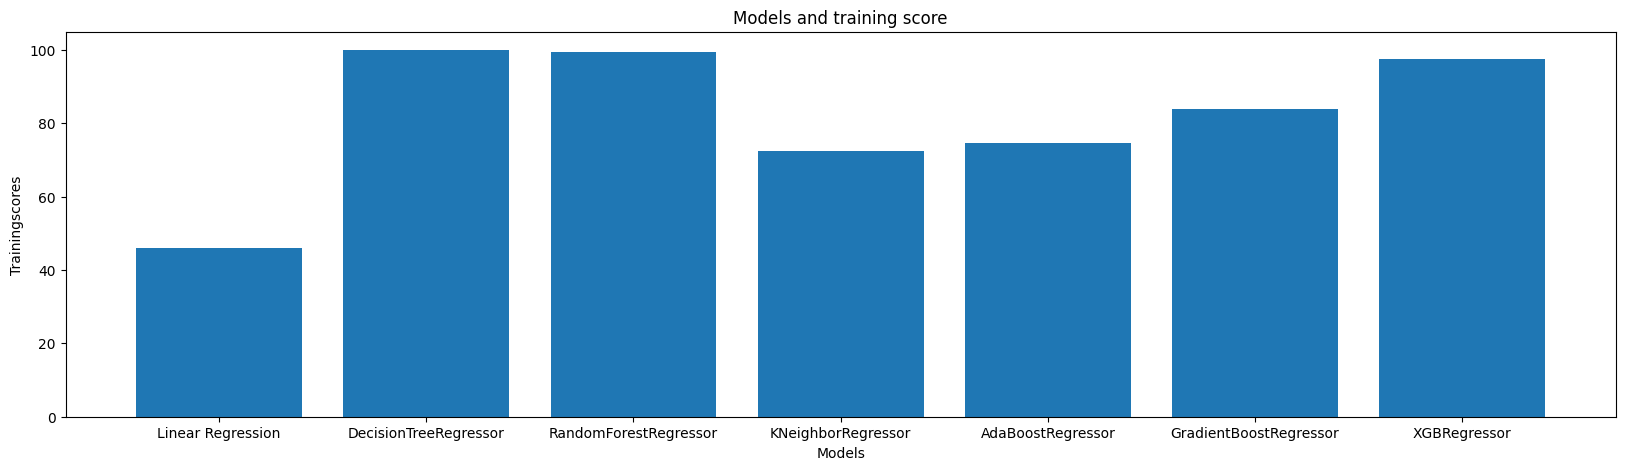

In [75]:
x=score.Model
y=score.TrainingScores
plt.figure(figsize=(20,5))
plt.bar(x,y)
plt.xlabel("Models")
plt.ylabel("Trainingscores")
plt.title("Models and training score")
plt.show()
           

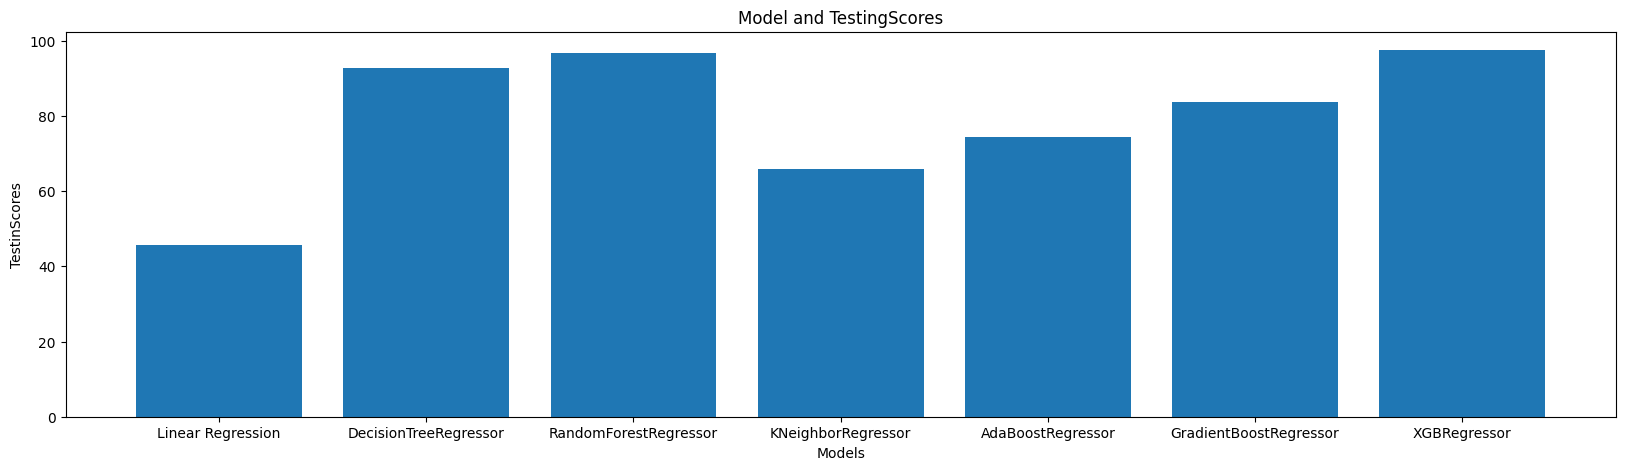

In [76]:
x=score.Model
y=score.TestingScores
plt.figure(figsize=(20,5))
plt.bar(x,y)
plt.xlabel("Models")
plt.ylabel("TestinScores")
plt.title("Model and TestingScores")
plt.show()

In [77]:
with open('mod.pkl', 'wb') as file:
    pickle.dump(model3, file)


with open('mod.pkl', 'rb') as file:
    loaded_model = pickle.load(file)
    
print(loaded_model.predict(x_test))

[168376.4   94987.32  76879.04 ... 136585.5  214558.76 160511.72]
